In [46]:
#realizar las importaciones necesarias
import sys
import nltk
import pandas as pd
import importlib

sys.path.insert(0, "/content")

import base_conocimientos
import interprete_intenciones
import motor_reglas
import preprocesamiento_texto

nltk.download('punkt')
nltk.download('punkt_tab')

importlib.reload(base_conocimientos)
importlib.reload(interprete_intenciones)
importlib.reload(motor_reglas)
importlib.reload(preprocesamiento_texto)

from base_conocimientos import intenciones
from interprete_intenciones import identificar_intencion
from motor_reglas import generar_respuesta



# Construir el dataset con las preguntas registradas
datos = []

for nombre_intencion, contenido in intenciones.items():
    for pregunta in contenido["dudas"]:
        datos.append({
            "texto": pregunta,
            "intencion": nombre_intencion
        })

# Convertir a tabla
dataset = pd.DataFrame(datos)

# Revisar cantidad de ejemplos e intenciones
print("Total de preguntas:", len(dataset))
print("Total de intenciones:", dataset["intencion"].nunique())

display(dataset)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


Total de preguntas: 94
Total de intenciones: 14


[nltk_data]   Package punkt_tab is already up-to-date!


,texto,intencion
0,hola,saludo
1,buenos dias,saludo
2,necesito ayuda,saludo
3,buenas tardes,saludo
4,tengo dudas,saludo
...,...,...
89,Qué pasa con mi tarjeta si solicito un reempla...,duda_reposicion
90,gracias,despedida
91,muchas gracias,despedida
92,eso es todo,despedida


In [47]:
from pathlib import Path

from clasificador_visual import cargar_clasificador_visual, clasificar_imagen

modelo_visual, categorias_visuales = cargar_clasificador_visual()

carpeta = Path("/content/dataset_cnn/validacion/pago_contactless")
ruta_imagen = sorted(carpeta.glob("*.png"))[0]

categoria = clasificar_imagen(ruta_imagen, modelo_visual, categorias_visuales)

print("Imagen:", ruta_imagen.name)
print("Categoría esperada:", ruta_imagen.parent.name)
print("Categoría predicha:", categoria)

Imagen: pexels-cottonbro-8657364.png
Categoría esperada: pago_contactless
Categoría predicha: pago_contactless


In [48]:
from pathlib import Path

from chat_multimodal import responder_consulta

pregunta = "¿Qué es la fecha de corte?"
ruta_imagen = Path(
    "/content/dataset_cnn/validacion/pago_contactless/"
    "pexels-cottonbro-8657364.png"
)

print("PRUEBA 1 — Solo texto")
print("Cliente:", pregunta)
print("Chatbot:", responder_consulta(pregunta))

print("\nPRUEBA 2 — Texto e imagen")
print("Cliente:", pregunta)
print("Imagen adjunta:", ruta_imagen.name)
print("Chatbot:", responder_consulta(pregunta, ruta_imagen))

PRUEBA 1 — Solo texto
Cliente: ¿Qué es la fecha de corte?
Chatbot: Es el día en que termina el periodo de registro de movimientos de tu tarjeta para poder generar tu estado de cuenta.

PRUEBA 2 — Texto e imagen
Cliente: ¿Qué es la fecha de corte?
Imagen adjunta: pexels-cottonbro-8657364.png
Chatbot: Es el día en que termina el periodo de registro de movimientos de tu tarjeta para poder generar tu estado de cuenta.
Categoría predicha: Pago sin contacto


In [ ]:
!python /content/chat.py

asistente : Hola este chat es para poder responder dudas sobre tus tarjetas de crédito.
Puede preguntar sobre pagos, intereses y alguno otros temas.
Escribe 'salir' para terminar la conversación.

Cliente: Traceback (most recent call last):
Traceback (most recent call last):
  File "/content/chat.py", line 7, in <module>
    iniciar_chatbot()
  File "/content/flujo_conversacional.py", line 11, in iniciar_chatbot
    pregunta = input("\nCliente: ").strip()
KeyboardInterrupt
^C


In [ ]:
# Utilizar la función de nuestro módulo
import preprocesamiento_texto

# Actualizar el dataset con el nuevo módulo
dataset["texto_procesado"] = dataset["texto"].apply(
    preprocesamiento_texto.preprocesar_texto
)

# Validar resultados
print("Total de preguntas:", len(dataset))
print("Total de intenciones:", dataset["intencion"].nunique())

vacios = dataset["texto_procesado"].fillna("").str.strip().eq("")
print("Textos procesados vacíos:", vacios.sum())

# Mostrar algunos ejemplos
display(dataset[["texto", "texto_procesado", "intencion"]].head(10))


Total de preguntas: 94
Total de intenciones: 14
Textos procesados vacíos: 0


,texto,texto_procesado,intencion
0,hola,hol,saludo
1,buenos dias,buen dias,saludo
2,necesito ayuda,necesit ayud,saludo
3,buenas tardes,buen tard,saludo
4,tengo dudas,teng dud,saludo
5,ayudame,ayudam,saludo
6,que es la tasa de interes,tas inter,duda_tasa_interes
7,que significa tasa de interes,signif tas inter,duda_tasa_interes
8,para que sirve la tasa de interes,sirv tas inter,duda_tasa_interes
9,Qué representa el porcentaje de interés de mi ...,represent porcentaj inter tarjet,duda_tasa_interes


In [ ]:
# Validar la calidad del dataset
print("Total de preguntas:", len(dataset))

# Revisar preguntas sin texto procesado
vacios = dataset["texto_procesado"].fillna("").str.strip().eq("").sum()
print("Textos procesados vacíos:", vacios)

# Revisar preguntas originales duplicadas
duplicados = dataset["texto"].duplicated().sum()
print("Preguntas duplicadas:", duplicados)

# Revisar ejemplos por intención
print("\nPreguntas por intención:")
print(dataset["intencion"].value_counts())

Total de preguntas: 94
Textos procesados vacíos: 0
Preguntas duplicadas: 0

Preguntas por intención:
intencion
duda_tasa_interes          7
duda_fecha_corte           7
duda_pago_minimo           7
duda_fecha_pago            7
duda_pago_sin_intereses    7
duda_calculo_intereses     7
duda_compras               7
duda_activacion            7
duda_tarjeta_digital       7
duda_cvv_dinamico          7
duda_reposicion            7
duda_domiciliaciones       7
saludo                     6
despedida                  4
Name: count, dtype: int64


In [ ]:
# Importar nuestro módulo de representación de texto
from representacion_texto import (
    crear_vectorizador,
    vectorizar_entrenamiento
)

# Crear el vectorizador TF-IDF
vectorizador = crear_vectorizador()

# Convertir las preguntas en vectores numéricos
X_tfidf = vectorizar_entrenamiento(
    dataset["texto_procesado"],
    vectorizador
)

# Mostrar resultados
print("Total de preguntas:", X_tfidf.shape[0])
print("Total de términos:", X_tfidf.shape[1])

# Mostrar algunos términos del vocabulario
print("\nPrimeros 20 términos:")
print(vectorizador.get_feature_names_out()[:20])


Total de preguntas: 94
Total de términos: 156

Primeros 20 términos:
['abon' 'activ' 'actualiz' 'adi' 'adicional' 'al' 'algun' 'anterior'
 'antes' 'aparec' 'aplic' 'aument' 'automat' 'ayud' 'ayudam' 'banc' 'buen'
 'cad' 'calcul' 'cambi']


In [ ]:
import pandas as pd

# Convertir la matriz TF-IDF en una tabla
matriz_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=vectorizador.get_feature_names_out()
)

# Mostrar las primeras 5 preguntas y 10 términos
display(matriz_tfidf.iloc[:5, :10])

# Verificar las dimensiones
print("Dimensiones de la matriz:", X_tfidf.shape)


,abon,activ,actualiz,adi,adicional,al,algun,anterior,antes,aparec
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Dimensiones de la matriz: (94, 156)


In [ ]:
# Seleccionar una pregunta relacionada con tasa de interés
indice = 6

print("Pregunta:", dataset.loc[indice, "texto"])
print("Texto procesado:", dataset.loc[indice, "texto_procesado"])

# Mostrar únicamente los términos con valores mayores a cero
valores = matriz_tfidf.iloc[indice]
valores = valores[valores > 0].sort_values(ascending=False)

print("\nTérminos y sus valores TF-IDF:")
display(valores)


Pregunta: que es la tasa de interes
Texto procesado: tas inter

Términos y sus valores TF-IDF:


,6
inter,0.707107
tas,0.707107


In [ ]:
from sklearn.model_selection import train_test_split

# Definir las preguntas procesadas y sus intenciones
X = dataset["texto_procesado"]
y = dataset["intencion"]

# Separar los datos para entrenamiento y pruebas
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verificar los resultados
print("Total de preguntas:", len(dataset))
print("Preguntas para entrenamiento:", len(X_entrenamiento))
print("Preguntas para pruebas:", len(X_prueba))

print("Intenciones en entrenamiento:", y_entrenamiento.nunique())
print("Intenciones en pruebas:", y_prueba.nunique())


Total de preguntas: 94
Preguntas para entrenamiento: 75
Preguntas para pruebas: 19
Intenciones en entrenamiento: 14
Intenciones en pruebas: 14


In [ ]:
from representacion_texto import (
    crear_vectorizador,
    vectorizar_entrenamiento,
    vectorizar_textos,
)

# Crear un nuevo vectorizador TF-IDF
vectorizador_ml = crear_vectorizador()

# Aprender el vocabulario únicamente de los datos de entrenamiento
X_train_tfidf = vectorizar_entrenamiento(
    X_entrenamiento,
    vectorizador_ml
)

# Transformar las preguntas de prueba con el mismo vocabulario
X_test_tfidf = vectorizar_textos(
    X_prueba,
    vectorizador_ml
)

# Verificar resultados
print("Matriz de entrenamiento:", X_train_tfidf.shape)
print("Matriz de pruebas:", X_test_tfidf.shape)
print("Términos aprendidos:", len(vectorizador_ml.get_feature_names_out()))

Matriz de entrenamiento: (75, 139)
Matriz de pruebas: (19, 139)
Términos aprendidos: 139


In [ ]:
# Importar nuestro módulo de clasificación
from clasificador_intenciones import entrenar_clasificador

# Entrenar Naive Bayes con los datos preparados
modelo_nb = entrenar_clasificador(
    X_train_tfidf,
    y_entrenamiento
)

# Verificar el entrenamiento
print("Modelo Naive Bayes entrenado correctamente")
print("Intenciones aprendidas:", len(modelo_nb.classes_))
print("Intenciones:", modelo_nb.classes_)


Modelo Naive Bayes entrenado correctamente
Intenciones aprendidas: 14
Intenciones: ['despedida' 'duda_activacion' 'duda_calculo_intereses' 'duda_compras'
 'duda_cvv_dinamico' 'duda_domiciliaciones' 'duda_fecha_corte'
 'duda_fecha_pago' 'duda_pago_minimo' 'duda_pago_sin_intereses'
 'duda_reposicion' 'duda_tarjeta_digital' 'duda_tasa_interes' 'saludo']


In [ ]:
# Importar la función de evaluación
from clasificador_intenciones import evaluar_clasificador

# Evaluar el modelo con las preguntas de prueba
predicciones = evaluar_clasificador(
    modelo_nb,
    X_test_tfidf,
    y_prueba
)

Exactitud (accuracy): 47.37 %

Reporte de clasificación:
                         precision    recall  f1-score   support

              despedida       0.00      0.00      0.00         1
        duda_activacion       0.00      0.00      0.00         1
 duda_calculo_intereses       0.50      1.00      0.67         1
           duda_compras       0.00      0.00      0.00         1
      duda_cvv_dinamico       1.00      1.00      1.00         2
   duda_domiciliaciones       1.00      0.50      0.67         2
       duda_fecha_corte       0.50      1.00      0.67         1
        duda_fecha_pago       0.50      0.50      0.50         2
       duda_pago_minimo       1.00      0.50      0.67         2
duda_pago_sin_intereses       0.00      0.00      0.00         1
        duda_reposicion       0.00      0.00      0.00         1
   duda_tarjeta_digital       0.00      0.00      0.00         1
      duda_tasa_interes       1.00      1.00      1.00         2
                 saludo       0.

In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

ruta = Path("/content/imagenes_procesadas")

imagenes_por_hash = defaultdict(list)

for archivo in ruta.rglob("*.png"):
    # Calcular una huella digital del archivo
    contenido = archivo.read_bytes()
    huella = hashlib.sha256(contenido).hexdigest()

    imagenes_por_hash[huella].append(
        str(archivo.relative_to(ruta))
    )

# Identificar archivos idénticos
duplicados = [
    archivos
    for archivos in imagenes_por_hash.values()
    if len(archivos) > 1
]

print("Total de imágenes:", sum(
    len(archivos) for archivos in imagenes_por_hash.values()
))
print("Grupos de duplicados exactos:", len(duplicados))

for grupo in duplicados:
    print("Duplicados:", grupo)


Total de imágenes: 0
Grupos de duplicados exactos: 0


In [ ]:
for conjunto in conjuntos:
    archivos = list((ruta / conjunto).rglob("*.png"))

    huellas[conjunto] = {
        hashlib.sha256(archivo.read_bytes()).hexdigest()
        for archivo in archivos
    }

    print(f"{conjunto}: {len(archivos)} imágenes")

print("\nDuplicados exactos entre conjuntos:")

for a, b in [
    ("entrenamiento", "validacion"),
    ("entrenamiento", "prueba"),
    ("validacion", "prueba")
]:
    repetidas = huellas[a] & huellas[b]
    print(f"{a} vs {b}: {len(repetidas)}")


entrenamiento: 85 imágenes
validacion: 19 imágenes
prueba: 21 imágenes

Duplicados exactos entre conjuntos:
entrenamiento vs validacion: 0
entrenamiento vs prueba: 0
validacion vs prueba: 0


In [ ]:

datos = []

for nombre_intencion, contenido in intenciones.items():
    for pregunta in contenido["dudas"]:
        datos.append({
            "texto": pregunta,
            "intencion": nombre_intencion
        })

dataset = pd.DataFrame(datos)
display(dataset)

,texto,intencion
0,hola,saludo
1,buenos dias,saludo
2,necesito ayuda,saludo
3,buenas tardes,saludo
4,tengo dudas,saludo
...,...,...
89,Qué pasa con mi tarjeta si solicito un reempla...,duda_reposicion
90,gracias,despedida
91,muchas gracias,despedida
92,eso es todo,despedida


In [35]:
import shutil
from google.colab import files

archivo_zip = shutil.make_archive(
    "/tmp/respaldo_content",
    "zip",
    root_dir="/content"
)

files.download(archivo_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
from pathlib import Path
from zipfile import ZipFile

with ZipFile("/content/dataset_cnn.zip") as archivo:
    archivo.extractall("/content")

ruta = Path("/content/dataset_cnn")

for conjunto in ["entrenamiento", "validacion", "prueba"]:
    total = sum(1 for _ in (ruta / conjunto).rglob("*.png"))
    print(f"{conjunto}: {total} imágenes")

entrenamiento: 85 imágenes
validacion: 19 imágenes
prueba: 21 imágenes


In [30]:
from pathlib import Path
from tensorflow import keras

ruta = Path("/content/dataset_cnn")
categorias = ["otras", "pago_contactless", "tarjeta_fisica"]

datos_entrenamiento = keras.utils.image_dataset_from_directory(
    ruta / "entrenamiento",
    class_names=categorias,
    image_size=(224, 224),
    batch_size=16,
    shuffle=True,
    seed=42,
)

datos_validacion = keras.utils.image_dataset_from_directory(
    ruta / "validacion",
    class_names=categorias,
    image_size=(224, 224),
    batch_size=16,
    shuffle=False,
)

print("Categorías:", datos_entrenamiento.class_names)

Found 85 files belonging to 3 classes.
Found 19 files belonging to 3 classes.
Categorías: ['otras', 'pago_contactless', 'tarjeta_fisica']


In [31]:
from tensorflow import keras

# Cargar EfficientNetB0 sin su clasificador original
base_visual = keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
base_visual.trainable = False

# Agregar el clasificador para nuestras categorías
entrada = keras.Input(shape=(224, 224, 3))
caracteristicas = base_visual(entrada, training=False)
caracteristicas = keras.layers.GlobalAveragePooling2D()(caracteristicas)
salida = keras.layers.Dense(len(categorias), activation="softmax")(caracteristicas)

modelo_visual = keras.Model(entrada, salida, name="clasificador_visual")
modelo_visual.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "clasificador_visual"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [32]:
modelo_visual.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

parada_temprana = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

historial_visual = modelo_visual.fit(
    datos_entrenamiento,
    validation_data=datos_validacion,
    epochs=20,
    callbacks=[parada_temprana],
)

perdida_val, exactitud_val = modelo_visual.evaluate(
    datos_validacion, verbose=0
)

print(f"Exactitud de validación: {exactitud_val:.2%}")
print(f"Pérdida de validación: {perdida_val:.4f}")

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.2824 - loss: 1.2175 - val_accuracy: 0.4211 - val_loss: 1.0176
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.6824 - loss: 0.8663 - val_accuracy: 0.6316 - val_loss: 0.8602
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8000 - loss: 0.6586 - val_accuracy: 0.6316 - val_loss: 0.7728
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8353 - loss: 0.5439 - val_accuracy: 0.7368 - val_loss: 0.7277
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.8588 - loss: 0.4425 - val_accuracy: 0.7895 - val_loss: 0.7076
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8824 - loss: 0.3942 - val_accuracy: 0.7895 - val_loss: 0.6979
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9059 - loss: 0.3449 - val_accuracy: 0.7895 - val_loss: 0.6995
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.9412 - loss: 0.3148 - val_accuracy: 0.7895 - val_loss: 0.6997
Epoch 9/20
6/

In [34]:
import json
from pathlib import Path

carpeta = Path("/content/modelo_visual")
carpeta.mkdir(parents=True, exist_ok=True)

ruta_modelo = carpeta / "clasificador_visual.keras"
ruta_categorias = carpeta / "categorias.json"

modelo_visual.save(ruta_modelo)
ruta_categorias.write_text(
    json.dumps(categorias, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Modelo guardado en:", ruta_modelo)
print("Categorías guardadas en:", ruta_categorias)

Modelo guardado en: /content/modelo_visual/clasificador_visual.keras
Categorías guardadas en: /content/modelo_visual/categorias.json


In [36]:
import json
from pathlib import Path

import numpy as np
from tensorflow import keras

# Cargar el modelo entrenado y el orden de sus categorías
carpeta_modelo = Path("/content/chatBot_JMZR/modelo_visual")
modelo_visual = keras.models.load_model(
    carpeta_modelo / "clasificador_visual.keras",
    compile=False,
)
categorias_visuales = json.loads(
    (carpeta_modelo / "categorias.json").read_text(encoding="utf-8")
)

# Cargar las imágenes de prueba en un orden fijo
datos_prueba_visual = keras.utils.image_dataset_from_directory(
    "/content/dataset_cnn/prueba",
    class_names=categorias_visuales,
    image_size=(224, 224),
    batch_size=16,
    shuffle=False,
)

# Obtener las etiquetas reales y las predicciones en el mismo orden
y_real_visual = np.concatenate([
    etiquetas.numpy() for _, etiquetas in datos_prueba_visual
])
puntajes_visual = modelo_visual.predict(datos_prueba_visual, verbose=0)
y_pred_visual = puntajes_visual.argmax(axis=1)

print("Imágenes de prueba:", len(y_real_visual))
print("Predicciones generadas:", len(y_pred_visual))
print("Categorías:", categorias_visuales)

Found 21 files belonging to 3 classes.
Imágenes de prueba: 21
Predicciones generadas: 21
Categorías: ['otras', 'pago_contactless', 'tarjeta_fisica']


Exactitud (accuracy): 80.95%
Aciertos: 17 de 21 imágenes

                  precision    recall  f1-score   support

           otras      0.714     0.714     0.714         7
pago_contactless      0.833     0.714     0.769         7
  tarjeta_fisica      0.875     1.000     0.933         7

        accuracy                          0.810        21
       macro avg      0.808     0.810     0.806        21
    weighted avg      0.808     0.810     0.806        21



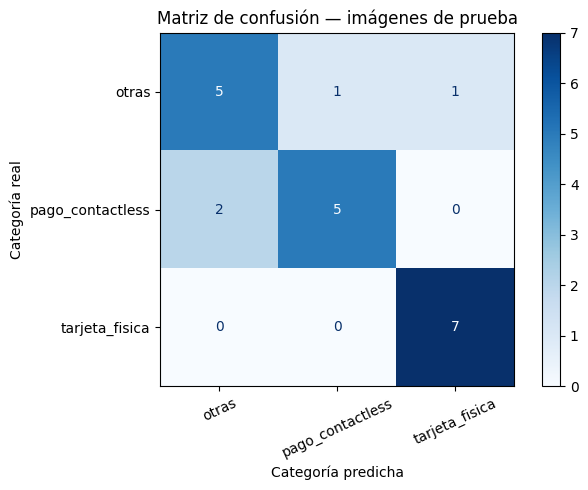

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

etiquetas = list(range(len(categorias_visuales)))
aciertos = (y_real_visual == y_pred_visual).sum()
exactitud = accuracy_score(y_real_visual, y_pred_visual)

print(f"Exactitud (accuracy): {exactitud:.2%}")
print(f"Aciertos: {aciertos} de {len(y_real_visual)} imágenes")
print()
print(classification_report(
    y_real_visual,
    y_pred_visual,
    labels=etiquetas,
    target_names=categorias_visuales,
    digits=3,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_real_visual,
    y_pred_visual,
    labels=etiquetas,
    display_labels=categorias_visuales,
    cmap="Blues",
    values_format="d",
    xticks_rotation=25,
    ax=ax,
)
ax.set_title("Matriz de confusión — imágenes de prueba")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")
fig.tight_layout()
plt.show()

In [49]:
from google.colab import drive
from datetime import datetime
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

drive.mount("/content/drive")

origen = Path("/content")
carpeta_drive = Path("/content/drive/MyDrive/Respaldos_Colab")
carpeta_drive.mkdir(parents=True, exist_ok=True)

fecha = datetime.now().strftime("%Y%m%d_%H%M%S")
ruta_zip = carpeta_drive / f"respaldo_content_{fecha}.zip"

with ZipFile(ruta_zip, "w", compression=ZIP_DEFLATED) as respaldo:
    for elemento in origen.iterdir():
        if elemento.name == "drive":
            continue  # Evita incluir Drive dentro de su propio respaldo

        if elemento.is_file():
            respaldo.write(elemento, elemento.relative_to(origen))
        elif elemento.is_dir():
            respaldo.write(elemento, elemento.relative_to(origen))
            for archivo in elemento.rglob("*"):
                respaldo.write(archivo, archivo.relative_to(origen))

with ZipFile(ruta_zip) as respaldo:
    if respaldo.testzip() is not None:
        raise RuntimeError("El ZIP no pasó la verificación de integridad.")

print("Respaldo verificado:", ruta_zip)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Respaldo verificado: /content/drive/MyDrive/Respaldos_Colab/respaldo_content_20261113_210458.zip
